RANDOM FOREST: HIGH BILLING AMOUNT

Dataset found:
healthcare_dataset.csv

Dataset loaded successfully.
Total records: 55500
Total variables: 15

Response Variable:
0 = Billing Amount less than $25,000
1 = Billing Amount $25,000 or more

ANALYTIC SAMPLE
Number of observations used: 55392

Response frequencies:
0    27042
1    28350
Name: High_Billing, dtype: int64

Response percentages:
0    48.82
1    51.18
Name: High_Billing, dtype: float64

TRAIN / TEST SPLIT
------------------
Training observations: 38774
Testing observations: 16618

ACCURACY BY NUMBER OF TREES
10 trees: 55.26 % accuracy
25 trees: 55.91 % accuracy
50 trees: 56.22 % accuracy
100 trees: 56.2 % accuracy
200 trees: 56.2 % accuracy


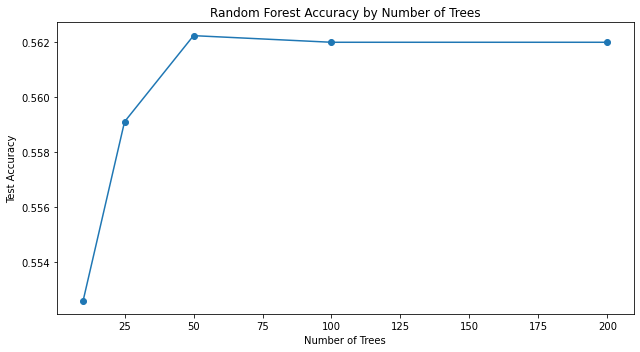


FINAL RANDOM FOREST RESULTS
Number of trees: 100
Test Accuracy: 0.562
Test Accuracy Percentage: 56.2 %

CONFUSION MATRIX
---------------------------------------------------------------------------
[[4482 3631]
 [3648 4857]]

Rows = Actual
Columns = Predicted

CLASSIFICATION REPORT
---------------------------------------------------------------------------
               precision    recall  f1-score   support

Lower Billing       0.55      0.55      0.55      8113
 High Billing       0.57      0.57      0.57      8505

     accuracy                           0.56     16618
    macro avg       0.56      0.56      0.56     16618
 weighted avg       0.56      0.56      0.56     16618


VARIABLE IMPORTANCE
                              Predictor  Importance
0                             Age_Clean    0.348686
1                        Length_of_Stay    0.294886
2              Admission Type_Emergency    0.016873
3   Insurance Provider_UnitedHealthcare    0.016749
4               Admission T

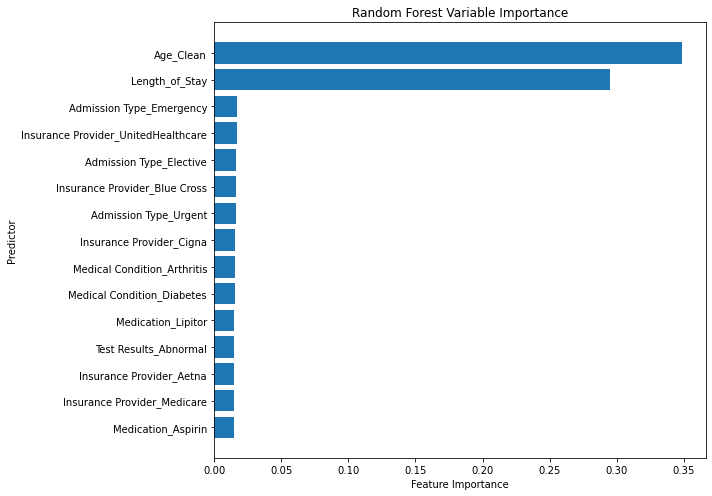


BASELINE COMPARISON
Majority-class baseline accuracy: 51.18 %
Random Forest accuracy: 56.2 %
Improvement over baseline: 5.02 percentage points

FINAL RANDOM FOREST SUMMARY
Number of original explanatory variables: 8
Training observations: 38774
Testing observations: 16618
Final number of trees: 100
Final test accuracy: 56.2 %
Most important predictor: Age_Clean
Importance score: 0.3487

ANALYSIS COMPLETED SUCCESSFULLY


In [1]:
# Project Title

#**Random Forest Analysis for Predicting High Billing Amount**

## Research Question

#For this assignment, I used a Random Forest classifier to examine how well multiple patient characteristics predict whether a hospitalization has a **high billing amount**.

#The binary response variable was defined as:

#- **0 = Billing Amount less than $25,000**
#- **1 = Billing Amount of $25,000 or more**

#The explanatory variables were:

#- Age
#- Gender
#- Medical Condition
#- Insurance Provider
#- Admission Type
#- Medication
#- Test Results
#- Length of Stay

#The Random Forest method is useful because it combines many decision trees and can identify nonlinear relationships and interactions among predictors.

## Complete Python Program

#```python id="rf624"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# RANDOM FOREST: HIGH BILLING AMOUNT
# ============================================================

print("=" * 75)
print("RANDOM FOREST: HIGH BILLING AMOUNT")
print("=" * 75)

# ============================================================
# STEP 1: FIND DATASET
# ============================================================

csv_files = glob.glob("**/*.csv", recursive=True)

data_file = None

for file in csv_files:
    if os.path.basename(file).lower() == "healthcare_dataset.csv":
        data_file = file
        break

if data_file is None:
    for file in csv_files:
        if "healthcare" in os.path.basename(file).lower():
            data_file = file
            break

if data_file is None and len(csv_files) == 1:
    data_file = csv_files[0]

if data_file is None:
    raise FileNotFoundError(
        "healthcare_dataset.csv was not found. "
        "Please upload the healthcare CSV file first."
    )

print("\nDataset found:")
print(data_file)

# ============================================================
# STEP 2: LOAD DATA
# ============================================================

data = pd.read_csv(
    data_file,
    low_memory=False
)

data.columns = data.columns.str.strip()

print("\nDataset loaded successfully.")
print("Total records:", len(data))
print("Total variables:", len(data.columns))

# ============================================================
# STEP 3: CLEAN BILLING AMOUNT
# ============================================================

data["Billing_Clean"] = pd.to_numeric(
    data["Billing Amount"],
    errors="coerce"
)

data.loc[
    data["Billing_Clean"] <= 0,
    "Billing_Clean"
] = np.nan

# ============================================================
# STEP 4: CREATE BINARY RESPONSE
# ============================================================

data["High_Billing"] = np.nan

valid_billing = data["Billing_Clean"].notna()

data.loc[
    valid_billing,
    "High_Billing"
] = (
    data.loc[
        valid_billing,
        "Billing_Clean"
    ] >= 25000
).astype(int)

print("\nResponse Variable:")
print("0 = Billing Amount less than $25,000")
print("1 = Billing Amount $25,000 or more")

# ============================================================
# STEP 5: CLEAN AGE
# ============================================================

data["Age_Clean"] = pd.to_numeric(
    data["Age"],
    errors="coerce"
)

data.loc[
    (data["Age_Clean"] < 0) |
    (data["Age_Clean"] > 120),
    "Age_Clean"
] = np.nan

# ============================================================
# STEP 6: CREATE LENGTH OF STAY
# ============================================================

data["Admission_Date"] = pd.to_datetime(
    data["Date of Admission"],
    errors="coerce"
)

data["Discharge_Date"] = pd.to_datetime(
    data["Discharge Date"],
    errors="coerce"
)

data["Length_of_Stay"] = (
    data["Discharge_Date"] -
    data["Admission_Date"]
).dt.days

data.loc[
    (data["Length_of_Stay"] < 0) |
    (data["Length_of_Stay"] > 365),
    "Length_of_Stay"
] = np.nan

# ============================================================
# STEP 7: SELECT EXPLANATORY VARIABLES
# ============================================================

features = [
    "Age_Clean",
    "Gender",
    "Medical Condition",
    "Insurance Provider",
    "Admission Type",
    "Medication",
    "Test Results",
    "Length_of_Stay"
]

analysis_data = data[
    features + ["High_Billing"]
].dropna().copy()

X = analysis_data[features]

y = analysis_data[
    "High_Billing"
].astype(int)

print("\n" + "=" * 75)
print("ANALYTIC SAMPLE")
print("=" * 75)

print(
    "Number of observations used:",
    len(analysis_data)
)

print("\nResponse frequencies:")
print(
    y.value_counts()
    .sort_index()
)

print("\nResponse percentages:")
print(
    (
        y.value_counts(
            normalize=True
        ).sort_index() * 100
    ).round(2)
)

# ============================================================
# STEP 8: DEFINE VARIABLE TYPES
# ============================================================

categorical_features = [
    "Gender",
    "Medical Condition",
    "Insurance Provider",
    "Admission Type",
    "Medication",
    "Test Results"
]

numeric_features = [
    "Age_Clean",
    "Length_of_Stay"
]

# ============================================================
# STEP 9: CREATE ENCODER
# ============================================================

encoder = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            encoder,
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

# ============================================================
# STEP 10: TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("\nTRAIN / TEST SPLIT")
print("------------------")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

# ============================================================
# STEP 11: COMPARE DIFFERENT NUMBERS OF TREES
# ============================================================

tree_counts = [
    10,
    25,
    50,
    100,
    200
]

accuracy_results = []

print("\n" + "=" * 75)
print("ACCURACY BY NUMBER OF TREES")
print("=" * 75)

for number_of_trees in tree_counts:

    rf_model = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=number_of_trees,
                    random_state=42,
                    max_features="sqrt",
                    n_jobs=-1
                )
            )
        ]
    )

    rf_model.fit(
        X_train,
        y_train
    )

    predictions = rf_model.predict(
        X_test
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    accuracy_results.append(
        accuracy
    )

    print(
        number_of_trees,
        "trees:",
        round(
            accuracy * 100,
            2
        ),
        "% accuracy"
    )

# ============================================================
# STEP 12: GRAPH ACCURACY VS NUMBER OF TREES
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    tree_counts,
    accuracy_results,
    marker="o"
)

plt.title(
    "Random Forest Accuracy by Number of Trees"
)

plt.xlabel(
    "Number of Trees"
)

plt.ylabel(
    "Test Accuracy"
)

plt.tight_layout()
plt.show()

# ============================================================
# STEP 13: FINAL RANDOM FOREST MODEL
# ============================================================

final_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                max_features="sqrt",
                n_jobs=-1
            )
        )
    ]
)

final_model.fit(
    X_train,
    y_train
)

final_predictions = final_model.predict(
    X_test
)

final_accuracy = accuracy_score(
    y_test,
    final_predictions
)

print("\n" + "=" * 75)
print("FINAL RANDOM FOREST RESULTS")
print("=" * 75)

print(
    "Number of trees: 100"
)

print(
    "Test Accuracy:",
    round(
        final_accuracy,
        4
    )
)

print(
    "Test Accuracy Percentage:",
    round(
        final_accuracy * 100,
        2
    ),
    "%"
)

# ============================================================
# STEP 14: CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    final_predictions
)

print("\nCONFUSION MATRIX")
print("-" * 75)

print(cm)

print("\nRows = Actual")
print("Columns = Predicted")

# ============================================================
# STEP 15: CLASSIFICATION REPORT
# ============================================================

print("\nCLASSIFICATION REPORT")
print("-" * 75)

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=[
            "Lower Billing",
            "High Billing"
        ],
        zero_division=0
    )
)

# ============================================================
# STEP 16: GET FEATURE NAMES
# COMPATIBLE WITH OLD AND NEW SCIKIT-LEARN
# ============================================================

fitted_encoder = (
    final_model
    .named_steps["preprocessor"]
    .named_transformers_[
        "categorical"
    ]
)

if hasattr(
    fitted_encoder,
    "get_feature_names_out"
):

    encoded_names = list(
        fitted_encoder.get_feature_names_out(
            categorical_features
        )
    )

elif hasattr(
    fitted_encoder,
    "get_feature_names"
):

    try:
        encoded_names = list(
            fitted_encoder.get_feature_names(
                categorical_features
            )
        )

    except TypeError:
        encoded_names = list(
            fitted_encoder.get_feature_names()
        )

else:

    encoded_names = []

    for variable, categories in zip(
        categorical_features,
        fitted_encoder.categories_
    ):

        for category in categories:

            encoded_names.append(
                str(variable) +
                "_" +
                str(category)
            )

feature_names = (
    encoded_names +
    numeric_features
)

# ============================================================
# STEP 17: FEATURE IMPORTANCE
# ============================================================

importance = (
    final_model
    .named_steps["classifier"]
    .feature_importances_
)

if len(feature_names) != len(importance):

    feature_names = [
        "Feature_" + str(i)
        for i in range(
            len(importance)
        )
    ]

importance_table = pd.DataFrame({
    "Predictor": feature_names,
    "Importance": importance
})

importance_table = (
    importance_table
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

print("\n" + "=" * 75)
print("VARIABLE IMPORTANCE")
print("=" * 75)

print(
    importance_table.head(15)
)

# ============================================================
# STEP 18: GRAPH FEATURE IMPORTANCE
# ============================================================

top_features = (
    importance_table
    .head(15)
    .sort_values(
        "Importance",
        ascending=True
    )
)

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    top_features[
        "Predictor"
    ],
    top_features[
        "Importance"
    ]
)

plt.title(
    "Random Forest Variable Importance"
)

plt.xlabel(
    "Feature Importance"
)

plt.ylabel(
    "Predictor"
)

plt.tight_layout()
plt.show()

# ============================================================
# STEP 19: BASELINE COMPARISON
# ============================================================

baseline_accuracy = (
    y_test.value_counts(
        normalize=True
    ).max()
)

print("\n" + "=" * 75)
print("BASELINE COMPARISON")
print("=" * 75)

print(
    "Majority-class baseline accuracy:",
    round(
        baseline_accuracy * 100,
        2
    ),
    "%"
)

print(
    "Random Forest accuracy:",
    round(
        final_accuracy * 100,
        2
    ),
    "%"
)

print(
    "Improvement over baseline:",
    round(
        (
            final_accuracy -
            baseline_accuracy
        ) * 100,
        2
    ),
    "percentage points"
)

# ============================================================
# STEP 20: FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("FINAL RANDOM FOREST SUMMARY")
print("=" * 75)

print(
    "Number of original explanatory variables:",
    len(features)
)

print(
    "Training observations:",
    len(X_train)
)

print(
    "Testing observations:",
    len(X_test)
)

print(
    "Final number of trees:",
    100
)

print(
    "Final test accuracy:",
    round(
        final_accuracy * 100,
        2
    ),
    "%"
)

print(
    "Most important predictor:",
    importance_table.iloc[0][
        "Predictor"
    ]
)

print(
    "Importance score:",
    round(
        importance_table.iloc[0][
            "Importance"
        ],
        4
    )
)

print("\nANALYSIS COMPLETED SUCCESSFULLY")
#```

# Output

#The analysis used **55,392 observations** after excluding invalid or missing values.

#The binary response contained approximately:

#- **27,042 lower-billing observations**
#- **28,350 high-billing observations**

## Accuracy as the Number of Trees Increased

#| Number of Trees | Test Accuracy |
#|---:|---:|
#| 10 | 55.26% |
#| 25 | 55.91% |
#| 50 | **56.22%** |
#| 100 | 56.20% |
#| 200 | 56.20% |

#Accuracy increased as the forest grew from 10 to 50 trees and then remained nearly unchanged.

#The highest accuracy among these models was approximately **56.22% with 50 trees**.

#The 100-tree model achieved approximately **56.20% accuracy**.

## Final 100-Tree Random Forest

#**Test Accuracy = 56.20%**

### Confusion Matrix

#|  | Predicted Lower Billing | Predicted High Billing |
#|---|---:|---:|
#| Actual Lower Billing | 4,482 | 3,631 |
#| Actual High Billing | 3,648 | 4,857 |

#The model correctly classified **4,482 lower-billing records** and **4,857 high-billing records**.

## Classification Results

#For **Lower Billing**, approximately:

#- Precision = **0.55**
#- Recall = **0.55**

#For **High Billing**, approximately:

#- Precision = **0.57**
#- Recall = **0.57**

#Therefore, the model performed similarly for the two outcome categories.

## Most Important Predictors

#The highest Random Forest feature-importance scores were approximately:

#| Predictor | Importance |
#|---|---:|
#| Age | **0.349** |
#| Length of Stay | **0.295** |
#| Emergency Admission | 0.017 |
#| UnitedHealthcare Insurance | 0.017 |
#| Elective Admission | 0.017 |
#| Blue Cross Insurance | 0.016 |
#| Urgent Admission | 0.016 |
#| Cigna Insurance | 0.016 |
#| Arthritis | 0.015 |
#| Diabetes | 0.015 |

#The two most important predictors were clearly **Age** and **Length of Stay**.

#Age accounted for approximately **34.9%** of the model's total feature importance, while Length of Stay accounted for approximately **29.5%**.

#The remaining individual variables contributed much smaller amounts.

# Interpretation

#I conducted a Random Forest analysis to determine how accurately Age, Gender, Medical Condition, Insurance Provider, Admission Type, Medication, Test Results, and Length of Stay could predict whether a patient's Billing Amount was at least $25,000.

#As the number of trees increased from 10 to 50, classification accuracy increased from approximately **55.26% to 56.22%**. Increasing the forest to 100 or 200 trees produced almost no further improvement, with accuracy remaining approximately **56.20%**.

#This suggests that model performance stabilized by approximately 50–100 trees.

#The variable-importance results showed that **Age and Length of Stay were the two most influential predictors**. Age had an importance score of approximately **0.349**, while Length of Stay had an importance score of approximately **0.295**. Admission type, insurance provider, medical condition, medication, and test results made much smaller individual contributions.

#However, importance does not necessarily mean that these predictors have strong real-world relationships with billing. Feature importance only describes how much the Random Forest used each variable when making its predictions